# Memory parity with relaxation, dephasing, and readout errors

A memory can relax toward zero, lose phase coherence, or be misread. Here we add those errors to the [ideal circuit](ideal_circuit_verification.ipynb) and see how much parity contrast survives.

We compare both schedule groups with a dephased-schedule control.  tables and figures go in `outputs/memory_robustness/`.

**Assumptions:** the noise values are examples rather than actual device calibrations. The system and schedule qubits, drive, and gates are otherwise ideal. We leave out noise during a memory's recording gate, heating, drift, routing overhead, and correlated errors.

## 1. Choose an example

We use six memories, total drive angle $\Omega T=3$, and offset angle $\alpha=\Omega\delta=\pi/2$. Ideally, one quarter of the shots are minus shots. Their mean memory parity is −1; the plus group's mean is $1/3$.

All times below are in microseconds. A 50 kHz drive gives a 9.55 μs recording train. Each offset rotation takes 5 μs, each recording takes 0.18 μs, and the final wait is 0.2 μs. These are editable timing assumptions.

We choose $T_1=100$ μs and pure-dephasing time $T_\phi=150$ μs.

$$\frac{1}{T_2}=\frac{1}{2T_1}+\frac{1}{T_\phi}.$$

That gives $T_2\approx85.7$ μs. Using a full $T_2$ decay as well as relaxation would count some loss twice. Each readout bit starts with a 2% error rate.

In [1]:
from pathlib import Path
import csv
import json
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

OUT = Path("outputs") / "memory_robustness"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 20261110
ATOL = 2e-10
MIN_PROB = 1e-12
OMEGA = 2 * np.pi * 0.05  # radians per microsecond
TRAIN_ANGLE = 3.0
OFFSET_ANGLE = np.pi / 2
RECORD_US = 0.18
WAIT_US = 0.20  # waiting after the last offset gate, before ideal basis rotations
T1_US = 100.0
TPHI_US = 150.0
MEMORY_READOUT = 0.02
SCHEDULE_READOUT = 0.02
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

def tphi_from_t1_t2(t1, t2):
    if t1 <= 0 or t2 <= 0 or t2 > 2 * t1:
        raise ValueError("This model needs positive times and T2 <= 2*T1.")
    rate = 1 / t2 - 1 / (2 * t1)
    return np.inf if rate == 0 else 1 / rate

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def save_csv(name, rows):
    with (OUT / name).open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

T2_US = 1 / (1 / (2 * T1_US) + 1 / TPHI_US)
print(f"Example T2: {T2_US:.3f} microseconds")
print(f"Train duration: {TRAIN_ANGLE / OMEGA:.3f} microseconds")
print("Python", platform.python_version(), "NumPy", np.__version__,
      "Matplotlib", matplotlib.__version__)

Matplotlib is building the font cache; this may take a moment.


Example T2: 85.714 microseconds
Train duration: 9.549 microseconds
Python 3.9.6 NumPy 2.0.2 Matplotlib 3.9.4


## 2. Build the circuit

The qubit order is $Q,S,M_1,\ldots,M_N$: schedule, system, then memories. Schedule B gets the extra system rotation first; schedule A gets it last. Each rotation in the recording train is followed by a CNOT into a fresh memory.

The gate functions are copied from the ideal notebook so this file runs on its own. They act on amplitudes and contain no parity formula. We keep $S$ until the circuit is built, then trace it out because we read only $Q$ and the memories.

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

def rx(angle):
    return np.cos(angle / 2) * I2 - 1j * np.sin(angle / 2) * X

def gate(state, matrix, target, nqubits, control=None, control_value=1):
    """Apply a gate to one qubit, optionally controlled by another qubit."""
    labels = np.arange(state.size)
    target_bit = 1 << (nqubits - 1 - target)
    use = (labels & target_bit) == 0
    if control is not None:
        control_bit = 1 << (nqubits - 1 - control)
        use &= ((labels & control_bit) != 0) == bool(control_value)
    zero = labels[use]
    one = zero | target_bit
    out = state.copy()
    out[zero] = matrix[0, 0] * state[zero] + matrix[0, 1] * state[one]
    out[one] = matrix[1, 0] * state[zero] + matrix[1, 1] * state[one]
    return out

def simulate(intervals, omega, delta, preparation="coherent", record=True):
    """Return the circuit state just before the final Hadamard on Q."""
    intervals = np.asarray(intervals, dtype=float)
    if intervals.ndim != 1 or not np.all(np.isfinite(intervals)):
        raise ValueError("Give the intervals as a finite, one-dimensional list.")
    if np.any(intervals < 0) or not np.isfinite(omega + delta) or delta < 0:
        raise ValueError("Intervals and the schedule delay must be nonnegative.")
    nqubits = len(intervals) + 2
    state = np.zeros(2 ** nqubits, dtype=complex)
    state[0] = 1
    if preparation == "coherent":
        state = gate(state, H, 0, nqubits)
    elif preparation == "B":
        state = gate(state, X, 0, nqubits)
    elif preparation != "A":
        raise ValueError("Choose coherent, A, or B preparation.")
    # B gets the extra rotation first.
    state = gate(state, rx(omega * delta), 1, nqubits, control=0)
    for k, interval in enumerate(intervals):
        state = gate(state, rx(omega * interval), 1, nqubits)
        if record:
            state = gate(state, X, k + 2, nqubits, control=1)
    # A gets the same extra rotation last.
    state = gate(state, rx(omega * delta), 1, nqubits,
                 control=0, control_value=0)
    return state

## 3. Count each memory's waiting time

A memory starts storing its record when its CNOT finishes. Earlier memories wait through more rotations and recording gates. Every memory also waits through the final offset gate and the last idle time.

Both branches share one laboratory gate schedule. We treat each CNOT as ideal and place it at the end of its time slot. Older memories decay during that slot; noise on the memory currently being recorded is omitted. The final basis rotations are instantaneous here. Readout errors are mistakes in the reported bit, not extra waiting time.

In [3]:
def storage_times(intervals, offset_slot_us, record_us=RECORD_US,
                  wait_us=WAIT_US):
    intervals = np.asarray(intervals, dtype=float)
    if np.any(intervals < 0) or min(offset_slot_us, record_us, wait_us) < 0:
        raise ValueError("All durations must be nonnegative.")
    N = len(intervals)
    later_drive = intervals.sum() - np.cumsum(intervals)
    later_recordings = np.arange(N - 1, -1, -1) * record_us
    return later_drive + later_recordings + offset_slot_us + wait_us

N_EXAMPLE = 6
intervals_example = np.full(N_EXAMPLE, TRAIN_ANGLE / OMEGA / N_EXAMPLE)
delta_example = OFFSET_ANGLE / OMEGA
ages_example = storage_times(intervals_example, delta_example)
show_table(["Memory", "Storage time (μs)"],
           [[f"M{k + 1}", f"{age:.3f}"] for k, age in enumerate(ages_example)])
print(f"Total memory exposure: {ages_example.sum():.3f} memory-microseconds")

| Memory | Storage time (μs) |
| --- | --- |
| M1 | 14.058 |
| M2 | 12.286 |
| M3 | 10.515 |
| M4 | 8.743 |
| M5 | 6.972 |
| M6 | 5.200 |

Total memory exposure: 57.773 memory-microseconds


## 4. Let the memories decay

A density matrix tracks the mixture of states caused by noise. In time $\tau$, relaxation transfers a fraction $\gamma=1-e^{-\tau/T_1}$ of the excited population to zero. Coherence shrinks by $e^{-\tau/T_2}$:

$$\rho\mapsto\begin{pmatrix}
\rho_{00}+\gamma\rho_{11} & e^{-\tau/T_2}\rho_{01}\\
e^{-\tau/T_2}\rho_{10} & (1-\gamma)\rho_{11}
\end{pmatrix}.$$

For several qubits, these entries are blocks of the larger matrix. Each memory can have its own lifetime. We assume independent, constant noise and no thermal excitation.

After recording, that memory never interacts again. Its noise can therefore be applied at the end using its full waiting time. We check this against a simulation that adds noise throughout the sequence.

In [4]:
def reduce_system(state, N):
    a = state.reshape(2, 2, 2 ** N)
    return np.einsum("asm,bsl->ambl", a, a.conj()).reshape(2 ** (N + 1), -1)

def ideal_density(intervals, omega, delta, dephased=False):
    N = len(intervals)
    if dephased:
        return sum(0.5 * reduce_system(simulate(intervals, omega, delta, label), N)
                   for label in ("A", "B"))
    return reduce_system(simulate(intervals, omega, delta), N)

def local_noise(rho, target, tau, t1, tphi):
    """Let one memory relax and lose phase coherence for tau microseconds."""
    if tau < 0 or t1 <= 0 or tphi <= 0:
        raise ValueError("Use a nonnegative duration and positive decay times.")
    n = int(np.log2(len(rho)))
    view = np.moveaxis(rho.reshape([2] * (2 * n)),
                       (target, n + target), (0, 1))
    out = view.copy()
    gamma = -np.expm1(-tau / t1)
    coherence = np.exp(-tau / (2 * t1) - tau / tphi)
    out[0, 0] = view[0, 0] + gamma * view[1, 1]
    out[1, 1] = (1 - gamma) * view[1, 1]
    out[0, 1] = coherence * view[0, 1]
    out[1, 0] = coherence * view[1, 0]
    return np.moveaxis(out, (0, 1), (target, n + target)).reshape(rho.shape)

def add_memory_noise(rho, ages, t1=np.inf, tphi=np.inf):
    t1s = np.broadcast_to(np.asarray(t1, dtype=float), len(ages))
    tphis = np.broadcast_to(np.asarray(tphi, dtype=float), len(ages))
    result = rho.copy()
    for k, age in enumerate(ages):
        result = local_noise(result, k + 1, age, t1s[k], tphis[k])
    return result

def axis_matrix(array, matrix, axis):
    return np.moveaxis(np.tensordot(matrix, array, axes=(1, axis)), 0, axis)

def density_gate(rho, matrix, target):
    n = int(np.log2(len(rho)))
    t = rho.reshape([2] * (2 * n))
    t = axis_matrix(t, matrix, target)
    t = axis_matrix(t, matrix.conj(), n + target)
    return t.reshape(rho.shape)

def x_readout_probabilities(rho):
    n = int(np.log2(len(rho)))
    for target in range(n):
        rho = density_gate(rho, H, target)
    probabilities = np.diag(rho).real.reshape([2] * n)
    assert probabilities.min() > -ATOL
    assert abs(probabilities.sum() - 1) < ATOL
    return np.maximum(probabilities, 0)

## 5. Add readout mistakes

For each bit, $e_{01}$ means reporting 1 when the true result is 0; $e_{10}$ means the reverse. In the assignment matrix, rows are reported bits and columns are true bits.

We rotate into the X basis, apply readout errors to the joint probabilities, and then select the reported plus or minus group. A misread memory bit flips parity. A misread schedule bit puts a shot in the wrong group.

The main plots use independent, symmetric errors. Later we also check unequal error directions.

In [5]:
def assignment(e01, e10=None):
    if e10 is None:
        e10 = e01
    if not (0 <= e01 <= 1 and 0 <= e10 <= 1):
        raise ValueError("Readout probabilities must lie between zero and one.")
    return np.array([[1 - e01, e10], [e01, 1 - e10]])

def reported_probabilities(probabilities, memory_errors=0.0, q_errors=0.0):
    N = probabilities.ndim - 1
    # A scalar means the same symmetric error for every memory.
    if np.isscalar(memory_errors):
        memory_matrices = [assignment(memory_errors)] * N
    else:
        memory_matrices = [assignment(*pair) for pair in memory_errors]
        if len(memory_matrices) != N:
            raise ValueError("Give one readout-error pair per memory.")
    q_matrix = assignment(q_errors) if np.isscalar(q_errors) else assignment(*q_errors)
    result = axis_matrix(probabilities, q_matrix, 0)
    for k, matrix in enumerate(memory_matrices):
        result = axis_matrix(result, matrix, k + 1)
    assert abs(result.sum() - probabilities.sum()) < ATOL
    return result

def parity_statistics(probabilities):
    grouped = probabilities.reshape(2, -1)
    signs = np.array([(-1) ** bin(m).count("1") for m in range(grouped.shape[1])])
    p = grouped.sum(axis=1)
    numerator = grouped @ signs
    mean = np.divide(numerator, p, out=np.full(2, np.nan), where=p > MIN_PROB)
    return dict(p=p, parity=mean, parity_joint=numerator,
                odd=(1 - mean) / 2, even=(1 + mean) / 2)

def calculate(intervals, omega, delta, t1=np.inf, tphi=np.inf,
              memory_errors=0.0, q_errors=0.0, wait_us=WAIT_US,
              record_us=RECORD_US, offset_slot_us=None, dephased=False):
    if offset_slot_us is None:
        offset_slot_us = delta
    ages = storage_times(intervals, offset_slot_us, record_us, wait_us)
    ideal = ideal_density(intervals, omega, delta, dephased)
    noisy = add_memory_noise(ideal, ages, t1, tphi)
    true_prob = x_readout_probabilities(noisy)
    observed_prob = reported_probabilities(true_prob, memory_errors, q_errors)
    return dict(ages=ages, ideal=ideal, noisy=noisy, true_prob=true_prob,
                observed_prob=observed_prob, true=parity_statistics(true_prob),
                observed=parity_statistics(observed_prob))

## 6. Check the noise code

We compare the matrix update with a separate Kraus-operator calculation on random states. Both should give the same valid density matrix: Hermitian, trace one, and no negative eigenvalues beyond rounding.

We also check simple limits. Excited population should decay as $e^{-\tau/T_1}$, and X coherence as $e^{-\tau/T_2}$. A readout check makes sure the two error directions are not swapped.

In [6]:
Z = np.diag([1.0, -1.0])
def kraus_noise(rho, target, tau, t1, tphi):
    gamma = -np.expm1(-tau / t1)
    phase = np.exp(-tau / tphi)
    amplitude_ops = [np.diag([1, np.sqrt(1 - gamma)]),
                     np.array([[0, np.sqrt(gamma)], [0, 0]])]
    phase_ops = [np.sqrt((1 + phase) / 2) * I2,
                 np.sqrt((1 - phase) / 2) * Z]
    return sum(density_gate(rho, b @ a, target)
               for a in amplitude_ops for b in phase_ops)

rng = np.random.default_rng(SEED)
channel_errors = []
for n in (1, 2, 3):
    for _ in range(8):
        a = rng.normal(size=(2**n, 2**n)) + 1j * rng.normal(size=(2**n, 2**n))
        rho = a @ a.conj().T
        rho /= np.trace(rho)
        target = int(rng.integers(n))
        tau, t1, tphi = rng.uniform(0, 50), rng.uniform(20, 200), rng.uniform(20, 250)
        got = local_noise(rho, target, tau, t1, tphi)
        other = kraus_noise(rho, target, tau, t1, tphi)
        channel_errors.append(float(np.max(np.abs(got - other))))
        assert abs(np.trace(got) - 1) < ATOL
        assert np.max(np.abs(got - got.conj().T)) < ATOL
        assert np.linalg.eigvalsh(got).min() > -ATOL
assert max(channel_errors) < ATOL
excited = np.diag([0.0, 1.0]).astype(complex)
plus = np.ones((2, 2), dtype=complex) / 2
tau = 13.0
assert abs(local_noise(excited, 0, tau, T1_US, TPHI_US)[1, 1]
           - np.exp(-tau / T1_US)) < ATOL
assert abs(np.trace(X @ local_noise(plus, 0, tau, T1_US, TPHI_US))
           - np.exp(-tau / T2_US)) < ATOL
assert np.allclose(assignment(0.03, 0.11) @ [1, 0], [0.97, 0.03])
assert np.allclose(assignment(0.03, 0.11) @ [0, 1], [0.11, 0.89])
print(f"24 random channel checks passed. Largest difference: {max(channel_errors):.3e}")
print("Population decay, coherence decay, and readout orientation checks passed.")

24 random channel checks passed. Largest difference: 3.331e-16
Population decay, coherence decay, and readout orientation checks passed.


## 7. Check the timing

For small circuits, we keep every qubit and add noise after each time slot using full gate matrices. We compare this with applying each memory's total decay at the end.

Agreement checks both the waiting times and the shortcut. The system and schedule qubits remain noiseless in both calculations.

In [7]:
def full_gate(matrix, target, n, control=None, value=1):
    basis = np.eye(2**n, dtype=complex)
    return np.column_stack([gate(basis[:, k], matrix, target, n, control, value)
                            for k in range(2**n)])

def trace_system_density(rho, N):
    d = 2**N
    return np.trace(rho.reshape(2, 2, d, 2, 2, d), axis1=1, axis2=4).reshape(2*d, 2*d)

def interleaved_density(intervals, omega, delta, t1, tphi,
                        record_us=RECORD_US, wait_us=WAIT_US):
    N = len(intervals)
    n = N + 2
    rho = np.zeros((2**n, 2**n), dtype=complex)
    rho[0, 0] = 1
    def unitary(r, matrix, target, control=None, value=1):
        u = full_gate(matrix, target, n, control, value)
        return u @ r @ u.conj().T
    def elapsed(r, duration):
        for memory in range(2, n):
            r = kraus_noise(r, memory, duration, t1, tphi)
        return r
    rho = unitary(rho, H, 0)
    rho = unitary(rho, rx(omega * delta), 1, 0, 1)
    rho = elapsed(rho, delta)
    for k, interval in enumerate(intervals):
        rho = unitary(rho, rx(omega * interval), 1)
        rho = elapsed(rho, interval)
        rho = elapsed(rho, record_us)
        rho = unitary(rho, X, k + 2, 1, 1)
    rho = unitary(rho, rx(omega * delta), 1, 0, 0)
    rho = elapsed(rho, delta + wait_us)
    return trace_system_density(rho, N)

time_errors = []
for N in (1, 2, 3):
    for _ in range(4):
        intervals = rng.uniform(0.02, 4.0, N)
        omega, delta = rng.uniform(0.1, 2.0), rng.uniform(0, 5.0)
        t1, tphi = rng.uniform(10, 200), rng.uniform(10, 200)
        end = calculate(intervals, omega, delta, t1, tphi)["noisy"]
        throughout = interleaved_density(intervals, omega, delta, t1, tphi)
        time_errors.append(float(np.max(np.abs(end - throughout))))
assert max(time_errors) < ATOL
print(f"12 timing checks passed. Largest state difference: {max(time_errors):.3e}")

12 timing checks passed. Largest state difference: 6.661e-16


## 8. Look at each source of loss on its own

We compare ideal memories, relaxation alone, pure dephasing alone, readout mistakes alone, and the combined case. The table uses six memories and the example values above.

The column “true minus” uses the actual schedule outcome with a perfect detector. “Reported minus” uses the bits the imperfect detectors would report. This separates loss of stored coherence from mistakes made when sorting and reading shots.

In [8]:
scenarios = {
    "ideal": {},
    "relaxation only": dict(t1=T1_US),
    "pure dephasing only": dict(tphi=TPHI_US),
    "both memory channels": dict(t1=T1_US, tphi=TPHI_US),
    "memory readout only": dict(memory_errors=MEMORY_READOUT),
    "schedule readout only": dict(q_errors=SCHEDULE_READOUT),
    "all three sources": dict(t1=T1_US, tphi=TPHI_US,
                               memory_errors=MEMORY_READOUT, q_errors=SCHEDULE_READOUT),
}
example_results = {}
example_rows = []
for name, settings in scenarios.items():
    result = calculate(intervals_example, OMEGA, delta_example, **settings)
    example_results[name] = result
    example_rows.append(dict(scenario=name,
        true_minus_parity=float(result["true"]["parity"][1]),
        reported_minus_parity=float(result["observed"]["parity"][1]),
        reported_plus_parity=float(result["observed"]["parity"][0]),
        reported_minus_fraction=float(result["observed"]["p"][1])))
show_table(["Case", "True minus", "Reported minus", "Reported plus", "Minus fraction"],
           [[r["scenario"]] + [f"{r[k]:.6f}" for k in list(r)[1:]] for r in example_rows])
save_csv("example_noise_sources.csv", example_rows)
control_example = calculate(intervals_example, OMEGA, delta_example,
                            dephased=True, **scenarios["all three sources"])
print("Dephased control, reported plus/minus parity:",
      control_example["observed"]["parity"])
assert np.max(np.abs(control_example["observed"]["parity"])) < ATOL

| Case | True minus | Reported minus | Reported plus | Minus fraction |
| --- | --- | --- | --- | --- |
| ideal | -1.000000 | -1.000000 | 0.333333 | 0.250000 |
| relaxation only | -0.749112 | -0.749112 | 0.249704 | 0.250000 |
| pure dephasing only | -0.680345 | -0.680345 | 0.226782 | 0.250000 |
| both memory channels | -0.509655 | -0.509655 | 0.169885 | 0.250000 |
| memory readout only | -1.000000 | -0.782758 | 0.260919 | 0.250000 |
| schedule readout only | -1.000000 | -0.923077 | 0.324324 | 0.260000 |
| all three sources | -0.509655 | -0.368249 | 0.129385 | 0.260000 |

Dephased control, reported plus/minus parity: [0. 0.]


## 9. Check against a simple formula

The storage loss in joint X parity is

$$C=\exp\left[-\sum_k\tau_k\left(\frac{1}{2T_{1,k}}+\frac{1}{T_{\phi,k}}\right)\right].$$

Here $\tau_k$ is memory $k$'s waiting time. Independent symmetric memory-readout errors add $R=\prod_k(1-2e_k)$. With perfect schedule readout, the minus and plus means are $-CR$ and $CRp_-/p_+$.

Let $a$ be the chance of reporting minus for a true plus shot, and $b$ the reverse. Then

$$m_{-,\mathrm{reported}}=-CR\frac{p_-(1-a-b)}{(1-b)p_-+ap_+}.$$

The denominator includes wrongly sorted plus shots. Treating the schedule bit as one more parity bit misses this change. We check the formula against the density-matrix result.

We also check that memory-only noise leaves the reduced state of $Q$ unchanged. This applies after the memories stop interacting; it does not say that gate errors or noise on $Q$ are harmless.

In [9]:
def analytic_means(ages, alpha, t1=np.inf, tphi=np.inf,
                   memory_errors=0.0, q_errors=0.0, dephased=False):
    ages = np.asarray(ages)
    t1s = np.broadcast_to(np.asarray(t1, dtype=float), len(ages))
    tphis = np.broadcast_to(np.asarray(tphi, dtype=float), len(ages))
    errors = np.broadcast_to(np.asarray(memory_errors, dtype=float), len(ages))
    C = np.exp(-np.sum(ages / (2 * t1s) + ages / tphis))
    R = np.prod(1 - 2 * errors)
    pm = 0.5 if dephased else 0.5 * np.sin(alpha / 2)**2
    probabilities = np.array([1 - pm, pm])
    numerator = np.zeros(2) if dephased else C * R * np.array([pm, -pm])
    matrix = assignment(q_errors) if np.isscalar(q_errors) else assignment(*q_errors)
    reported_p = matrix @ probabilities
    reported_num = matrix @ numerator
    means = np.divide(reported_num, reported_p, out=np.full(2, np.nan),
                      where=reported_p > MIN_PROB)
    return dict(parity=means, p=reported_p, storage_factor=C, memory_readout_factor=R)

def reduced_q(rho):
    d = len(rho) // 2
    return np.trace(rho.reshape(2, d, 2, d), axis1=1, axis2=3)

formula_errors, q_state_errors = [], []
for N in range(1, 6):
    for _ in range(6):
        intervals = rng.uniform(0.01, 5, N)
        omega, alpha = rng.uniform(0.1, 1), rng.uniform(0.1, 2*np.pi - 0.1)
        t1s, tphis = rng.uniform(20, 250, N), rng.uniform(20, 300, N)
        mem_errors = rng.uniform(0, 0.08, N)
        q_errors = tuple(rng.uniform(0, 0.08, 2))
        got = calculate(intervals, omega, alpha / omega, t1s, tphis,
                        memory_errors=[(e, e) for e in mem_errors], q_errors=q_errors)
        expected = analytic_means(got["ages"], alpha, t1s, tphis, mem_errors, q_errors)
        formula_errors.append(float(np.max(np.abs(got["observed"]["parity"] - expected["parity"]))))
        q_state_errors.append(float(np.max(np.abs(reduced_q(got["ideal"]) - reduced_q(got["noisy"])))))
        assert abs(np.trace(got["noisy"]) - 1) < ATOL
        assert np.linalg.eigvalsh(got["noisy"]).min() > -ATOL
assert max(formula_errors + q_state_errors) < ATOL
print(f"30 random noisy circuits passed. Largest parity difference: {max(formula_errors):.3e}")
print(f"Largest change in the reduced Q state: {max(q_state_errors):.3e}")

30 random noisy circuits passed. Largest parity difference: 4.441e-16
Largest change in the reduced Q state: 2.776e-16


## 10. Add more memories

These points come from the density-matrix calculation. We vary the number of records from one to eight, keeping the drive time, offset, and lifetimes fixed. More memories add waiting time and more bits that can be misread.

The dephased control uses the same noise settings. Separation from this control is useful evidence, but parity alone does not rule out every possible alternative preparation.

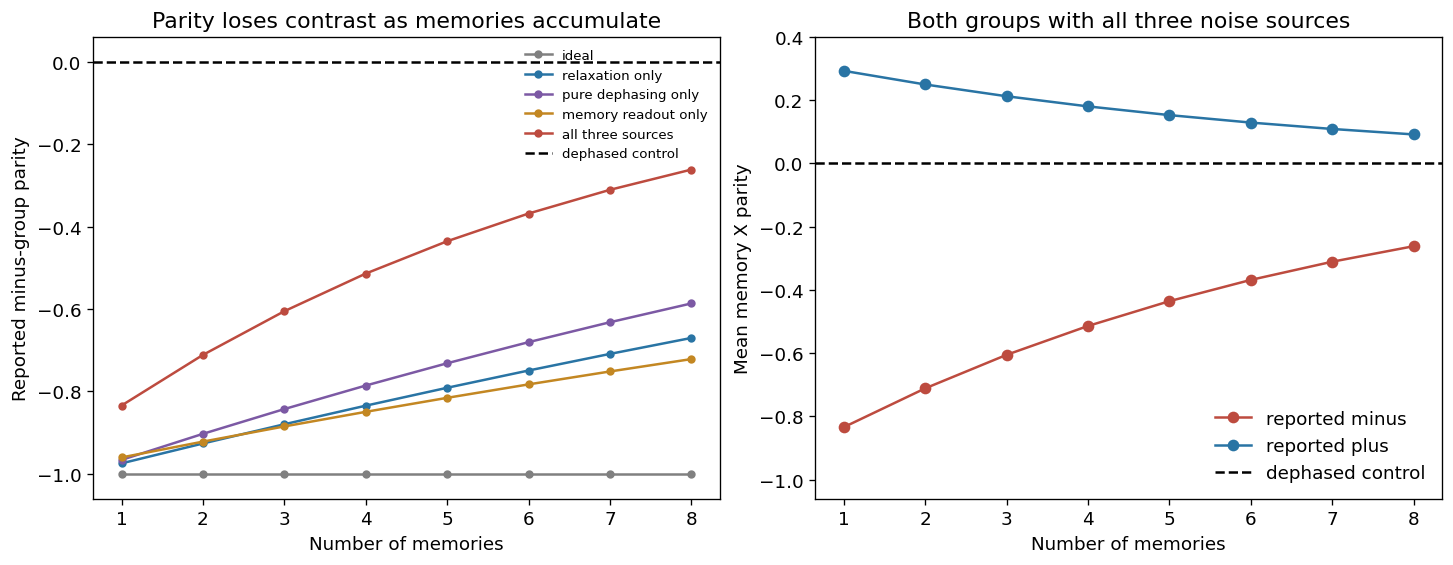

| N | Reported minus parity | Reported plus parity | Minus fraction |
| --- | --- | --- | --- |
| 1 | -0.8340 | 0.2930 | 0.2600 |
| 2 | -0.7112 | 0.2499 | 0.2600 |
| 3 | -0.6052 | 0.2126 | 0.2600 |
| 4 | -0.5139 | 0.1806 | 0.2600 |
| 5 | -0.4355 | 0.1530 | 0.2600 |
| 6 | -0.3682 | 0.1294 | 0.2600 |
| 7 | -0.3107 | 0.1092 | 0.2600 |
| 8 | -0.2617 | 0.0919 | 0.2600 |

In [10]:
sweep_rows = []
for N in range(1, 9):
    intervals = np.full(N, TRAIN_ANGLE / OMEGA / N)
    for name, settings in scenarios.items():
        result = calculate(intervals, OMEGA, delta_example, **settings)
        expected = analytic_means(result["ages"], OFFSET_ANGLE, **settings)
        assert np.max(np.abs(result["observed"]["parity"] - expected["parity"])) < ATOL
        sweep_rows.append(dict(N=N, scenario=name, minus=float(result["observed"]["parity"][1]),
                               plus=float(result["observed"]["parity"][0]),
                               p_minus=float(result["observed"]["p"][1]),
                               memory_exposure_us=float(result["ages"].sum())))
    control = calculate(intervals, OMEGA, delta_example,
                        dephased=True, **scenarios["all three sources"])
    assert np.max(np.abs(control["observed"]["parity"])) < ATOL
save_csv("parity_vs_memory_count.csv", sweep_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
styles = [("ideal", "0.5"), ("relaxation only", "#2974a4"),
          ("pure dephasing only", "#7c59a4"), ("memory readout only", "#c38722"),
          ("all three sources", "#bd4b3f")]
for name, color in styles:
    subset = [r for r in sweep_rows if r["scenario"] == name]
    axes[0].plot([r["N"] for r in subset], [r["minus"] for r in subset],
                 "o-", color=color, ms=4, label=name)
axes[0].axhline(0, color="black", ls="--", label="dephased control")
axes[0].set(xlabel="Number of memories", ylabel="Reported minus-group parity",
            title="Parity loses contrast as memories accumulate", ylim=(-1.06, 0.06))
axes[0].legend(frameon=False, fontsize=8)
all_rows = [r for r in sweep_rows if r["scenario"] == "all three sources"]
axes[1].plot([r["N"] for r in all_rows], [r["minus"] for r in all_rows], "o-",
             color="#bd4b3f", label="reported minus")
axes[1].plot([r["N"] for r in all_rows], [r["plus"] for r in all_rows], "o-",
             color="#2974a4", label="reported plus")
axes[1].axhline(0, color="black", ls="--", label="dephased control")
axes[1].set(xlabel="Number of memories", ylabel="Mean memory X parity",
            title="Both groups with all three noise sources", ylim=(-1.06, 0.4))
axes[1].legend(frameon=False)
fig.savefig(OUT / "parity_vs_memory_count.png", dpi=180)
plt.show()
show_table(["N", "Reported minus parity", "Reported plus parity", "Minus fraction"],
           [[r["N"], f"{r['minus']:.4f}", f"{r['plus']:.4f}", f"{r['p_minus']:.4f}"]
            for r in all_rows])

## 11. Vary waiting time and readout quality

The left panel varies the final wait and memory $T_2$. It keeps $T_1=200$ μs, so all plotted values obey $T_2\le2T_1$. The right panel varies memory and schedule readout errors separately.

These larger grids use the formula we just checked. We also verify several grid points directly with the density matrix. Contour labels show the magnitude of minus parity; they are not hardware requirements.

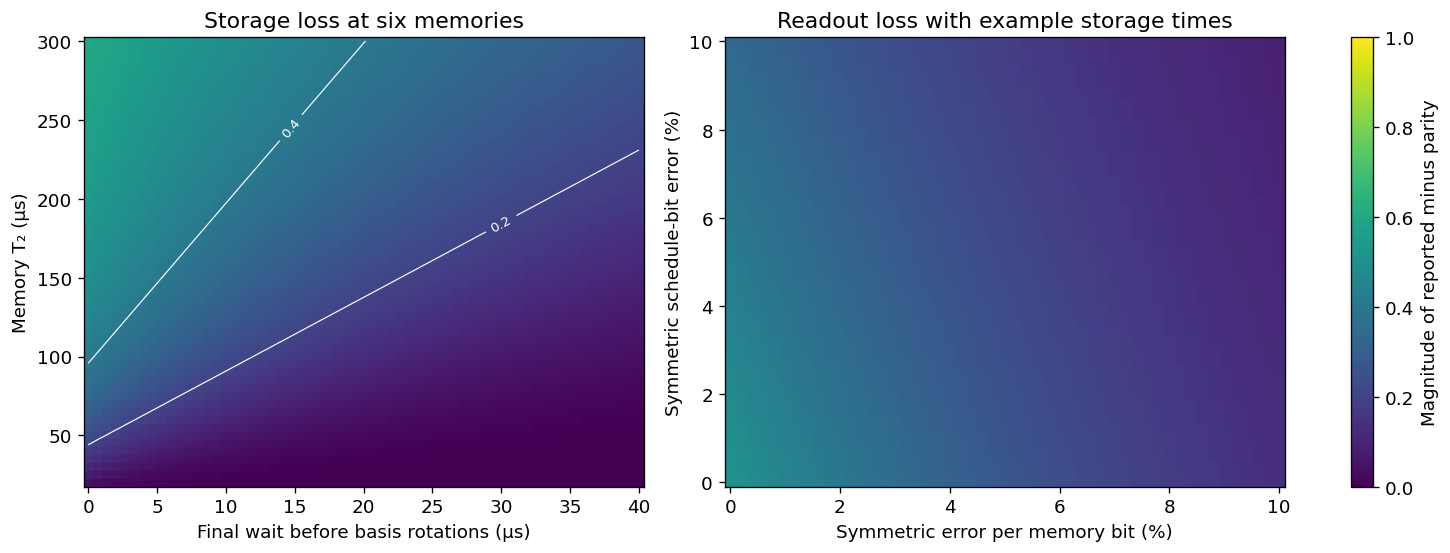

In [11]:
N_GRID = 6
intervals_grid = np.full(N_GRID, TRAIN_ANGLE / OMEGA / N_GRID)
waits = np.linspace(0, 40, 61)
t2s = np.linspace(20, 300, 57)
contrast = np.empty((len(t2s), len(waits)))
for i, t2 in enumerate(t2s):
    tp = tphi_from_t1_t2(200.0, t2)
    for j, wait in enumerate(waits):
        ages = storage_times(intervals_grid, delta_example, wait_us=wait)
        contrast[i, j] = -analytic_means(ages, OFFSET_ANGLE, 200.0, tp,
                                        MEMORY_READOUT, SCHEDULE_READOUT)["parity"][1]
errors_grid = np.linspace(0, 0.10, 51)
readout_contrast = np.array([[-analytic_means(ages_example, OFFSET_ANGLE,
                              T1_US, TPHI_US, em, eq)["parity"][1]
                             for em in errors_grid] for eq in errors_grid])
grid_errors = []
for wait, t2 in [(0, 20), (40, 300), (10, 80), (20, 150)]:
    tp = tphi_from_t1_t2(200, t2)
    got = calculate(intervals_grid, OMEGA, delta_example, 200, tp,
                    MEMORY_READOUT, SCHEDULE_READOUT, wait_us=wait)
    expected = analytic_means(got["ages"], OFFSET_ANGLE, 200, tp,
                              MEMORY_READOUT, SCHEDULE_READOUT)
    grid_errors.append(float(abs(got["observed"]["parity"][1] - expected["parity"][1])))
assert max(grid_errors) < ATOL
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
im = axes[0].pcolormesh(waits, t2s, contrast, shading="auto", vmin=0, vmax=1, cmap="viridis")
axes[0].set(xlabel="Final wait before basis rotations (μs)", ylabel="Memory T₂ (μs)",
            title="Storage loss at six memories")
cont = axes[0].contour(waits, t2s, contrast, levels=[0.2, 0.4, 0.6], colors="white", linewidths=0.7)
axes[0].clabel(cont, fontsize=8)
axes[1].pcolormesh(100*errors_grid, 100*errors_grid, readout_contrast,
                   shading="auto", vmin=0, vmax=1, cmap="viridis")
axes[1].set(xlabel="Symmetric error per memory bit (%)", ylabel="Symmetric schedule-bit error (%)",
            title="Readout loss with example storage times")
fig.colorbar(im, ax=axes, label="Magnitude of reported minus parity")
fig.savefig(OUT / "storage_and_readout_sensitivity.png", dpi=180)
plt.show()
np.savez_compressed(OUT / "sensitivity_grids.npz", waits_us=waits, t2_us=t2s,
                    contrast=contrast, readout_error=errors_grid, readout_contrast=readout_contrast)

## 12. Make minus shots rare

With a small offset, true minus shots are rare. Misclassified plus shots can then dominate the reported minus group, even with a modest readout error.

Here the offset-gate slot stays at 5 μs while its rotation angle changes. This isolates the sorting effect and assumes the drive amplitude can change within that slot. It differs from changing the duration at fixed drive strength.

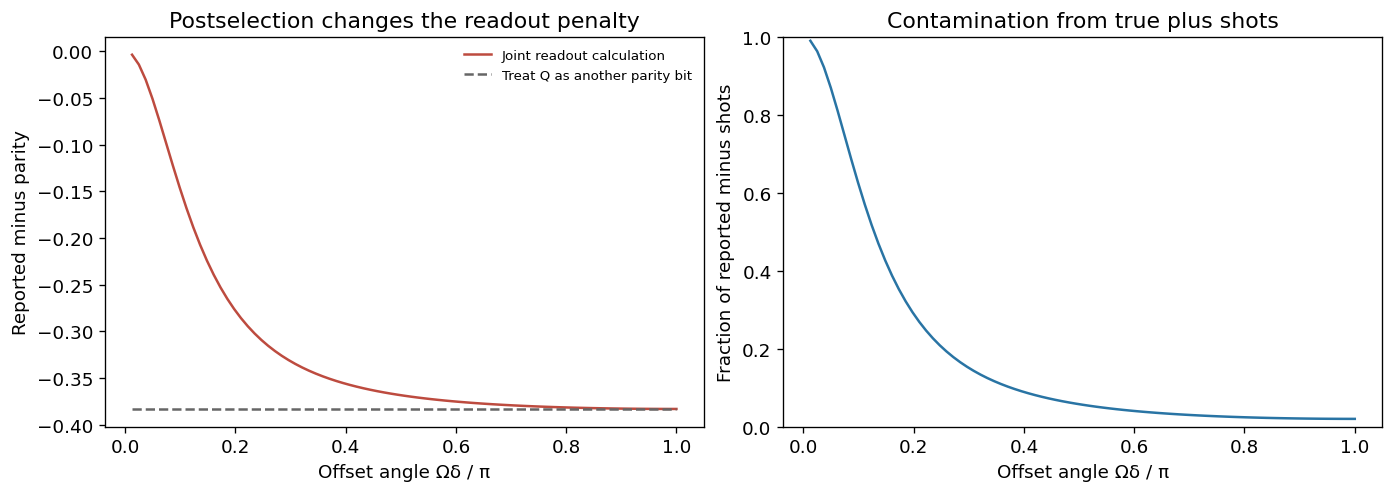

In [12]:
alphas = np.linspace(0.04, np.pi, 81)
offset_rows = []
for alpha in alphas:
    got = calculate(intervals_example, OMEGA, alpha / OMEGA,
                    T1_US, TPHI_US, MEMORY_READOUT, SCHEDULE_READOUT,
                    offset_slot_us=delta_example)
    expected = analytic_means(got["ages"], alpha, T1_US, TPHI_US,
                              MEMORY_READOUT, SCHEDULE_READOUT)
    assert np.max(np.abs(got["observed"]["parity"] - expected["parity"])) < ATOL
    true_pm = 0.5 * np.sin(alpha / 2)**2
    false_minus = SCHEDULE_READOUT * (1 - true_pm)
    offset_rows.append(dict(alpha=float(alpha), true_minus_fraction=float(true_pm),
        reported_minus_fraction=float(got["observed"]["p"][1]),
        fraction_of_reported_minus_from_plus=float(false_minus / got["observed"]["p"][1]),
        measured_minus=float(got["observed"]["parity"][1]),
        naive_extra_bit=float(-expected["storage_factor"] * (1 - 2*MEMORY_READOUT)**N_EXAMPLE
                               * (1 - 2*SCHEDULE_READOUT))))
save_csv("offset_and_misclassification.csv", offset_rows)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), constrained_layout=True)
x = alphas / np.pi
axes[0].plot(x, [r["measured_minus"] for r in offset_rows], color="#bd4b3f", label="Joint readout calculation")
axes[0].plot(x, [r["naive_extra_bit"] for r in offset_rows], "--", color="0.4", label="Treat Q as another parity bit")
axes[0].set(xlabel="Offset angle Ωδ / π", ylabel="Reported minus parity", title="Postselection changes the readout penalty")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(x, [r["fraction_of_reported_minus_from_plus"] for r in offset_rows], color="#2974a4")
axes[1].set(xlabel="Offset angle Ωδ / π", ylabel="Fraction of reported minus shots",
            title="Contamination from true plus shots", ylim=(0, 1))
fig.savefig(OUT / "schedule_readout_contamination.png", dpi=180)
plt.show()

## 13. Try uneven intervals and unequal readout errors

We now vary the gaps, memory lifetimes, and both error directions. The full probability calculation still works, although the simple symmetric-readout factor no longer applies.

The dephased control has uniform ideal X-basis memory strings. Independent asymmetric readout gives it mean parity $\prod_k(e_{10,k}-e_{01,k})$, so its measured baseline need not be zero.

We also check zero noise, complete phase loss, random readout, and zero offset. At zero offset there are no true minus shots; any reported minus shots are sorting mistakes.

In [13]:
uneven = np.array([0.2, 2.1, 0.7, 4.0])
t1_var = np.array([60, 100, 180, 90])
tphi_var = np.array([80, 120, 250, 160])
mem_asym = [(0.01, 0.04), (0.03, 0.02), (0.02, 0.05), (0.01, 0.03)]
q_asym = (0.015, 0.035)
asym = calculate(uneven, OMEGA, delta_example, t1_var, tphi_var, mem_asym, q_asym)
asym_control = calculate(uneven, OMEGA, delta_example, t1_var, tphi_var,
                         mem_asym, q_asym, dephased=True)
control_bias = np.prod([b-a for a, b in mem_asym])
assert np.max(np.abs(asym_control["observed"]["parity"] - control_bias)) < ATOL
show_table(["Uneven/asymmetric example", "Reported plus parity", "Reported minus parity"],
           [[name] + [f"{v:.9f}" for v in r["observed"]["parity"]]
            for name, r in [("coherent", asym), ("dephased control", asym_control)]])
print(f"Expected asymmetric detector bias in the control: {control_bias:.3e}")

ideal = calculate(uneven, OMEGA, delta_example)
assert abs(ideal["observed"]["parity"][1] + 1) < ATOL
assert abs(ideal["observed"]["parity"][0] - 1/3) < ATOL
lost_phase = calculate(uneven, OMEGA, delta_example, tphi=1e-6)
assert np.max(np.abs(lost_phase["observed"]["parity"])) < ATOL
random_memory = calculate(uneven, OMEGA, delta_example, memory_errors=0.5)
random_schedule = calculate(uneven, OMEGA, delta_example, q_errors=0.5)
assert np.max(np.abs(random_memory["observed"]["parity"])) < ATOL
assert np.max(np.abs(random_schedule["observed"]["parity"])) < ATOL
zero_offset = calculate(uneven, OMEGA, 0.0, T1_US, TPHI_US,
                        MEMORY_READOUT, SCHEDULE_READOUT)
assert zero_offset["true"]["p"][1] < MIN_PROB
assert np.isnan(zero_offset["true"]["parity"][1])
assert abs(zero_offset["observed"]["p"][1] - SCHEDULE_READOUT) < ATOL
assert abs(zero_offset["observed"]["parity"][1]) < ATOL
print("Zero-noise, phase-loss, random-detector, and zero-offset checks passed.")

| Uneven/asymmetric example | Reported plus parity | Reported minus parity |
| --- | --- | --- |
| coherent | 0.151743818 | -0.449222510 |
| dephased control | -0.000000180 | -0.000000180 |

Expected asymmetric detector bias in the control: -1.800e-07
Zero-noise, phase-loss, random-detector, and zero-offset checks passed.


## 14. Turn the contrast into a rough shot budget

For a group with mean parity $m$, each shot is either +1 or −1, so its variance is $1-m^2$. If a fraction $p$ of all runs lands in that group, $M$ total runs give approximately $Mp$ selected shots.

For separate coherent and dephased datasets with the **same total number of runs each**, a rough planning estimate is

$$M\approx \frac{z^2}{(m_c-m_d)^2}\left[\frac{1-m_c^2}{p_c}+\frac{1-m_d^2}{p_d}\right].$$

Here $z=5$ requests an expected separation of five standard errors under this model. This is a planning calculation, not a guaranteed significance or a substitute for a prespecified statistical test. Calibration uncertainty and systematic errors are absent. We require at least 30 expected selected shots in each dataset to avoid using this approximation for tiny samples.

We then draw 20,000 synthetic runs for each condition and report conditional parity with a 95% Wilson interval. These are simulated observations, not experimental data. The ideal bit-string probabilities are not shown as measured data.

In [14]:
shot_plan = []
for r in all_rows:
    pc, mc = r["p_minus"], r["minus"]
    pd, md_control = 0.5, 0.0
    separation = abs(mc - md_control)
    needed = 25 * ((1 - mc**2) / pc + (1 - md_control**2) / pd) / separation**2
    needed = int(np.ceil(max(needed, 30/pc, 30/pd)))
    shot_plan.append(dict(N=r["N"], minus_parity=mc,
                          total_runs_per_condition=needed, total_runs_both=2*needed))
show_table(["Memories", "Minus parity", "Runs per condition", "Runs for both datasets"],
           [[r["N"], f"{r['minus_parity']:.4f}", r["total_runs_per_condition"],
             r["total_runs_both"]] for r in shot_plan])
save_csv("shot_planning.csv", shot_plan)

def parity_wilson(even, total, z=1.96):
    f = even / total
    denominator = 1 + z*z/total
    centre = (f + z*z/(2*total)) / denominator
    radius = z*np.sqrt(f*(1-f)/total + z*z/(4*total*total)) / denominator
    return 2*f-1, 2*(centre-radius)-1, 2*(centre+radius)-1

shot_rng = np.random.default_rng(SEED + 10)
shot_rows = []
for name, result in [("coherent", example_results["all three sources"]),
                      ("dephased control", control_example)]:
    probabilities = result["observed_prob"]
    counts = shot_rng.multinomial(20000, probabilities.ravel()/probabilities.sum()).reshape(2, -1)
    even_indices = [m for m in range(counts.shape[1]) if bin(m).count("1") % 2 == 0]
    for q, group in enumerate(["plus", "minus"]):
        total = int(counts[q].sum())
        even = int(counts[q, even_indices].sum())
        mean, low, high = parity_wilson(even, total)
        shot_rows.append(dict(condition=name, group=group, selected_shots=total,
                               measured_mean=mean, interval_low=low, interval_high=high,
                               model_mean=float(result["observed"]["parity"][q])))
show_table(["Condition", "Group", "Selected shots", "Sample parity", "95% interval", "Model mean"],
           [[r["condition"], r["group"], r["selected_shots"], f"{r['measured_mean']:.4f}",
             f"[{r['interval_low']:.4f}, {r['interval_high']:.4f}]", f"{r['model_mean']:.4f}"]
            for r in shot_rows])
save_csv("synthetic_shots.csv", shot_rows)

| Memories | Minus parity | Runs per condition | Runs for both datasets |
| --- | --- | --- | --- |
| 1 | -0.8340 | 116 | 232 |
| 2 | -0.7112 | 193 | 386 |
| 3 | -0.6052 | 303 | 606 |
| 4 | -0.5139 | 458 | 916 |
| 5 | -0.4355 | 675 | 1350 |
| 6 | -0.3682 | 982 | 1964 |
| 7 | -0.3107 | 1418 | 2836 |
| 8 | -0.2617 | 2039 | 4078 |

| Condition | Group | Selected shots | Sample parity | 95% interval | Model mean |
| --- | --- | --- | --- | --- | --- |
| coherent | plus | 14736 | 0.1329 | [0.1168, 0.1488] | 0.1294 |
| coherent | minus | 5264 | -0.3533 | [-0.3783, -0.3278] | -0.3682 |
| dephased control | plus | 9972 | 0.0174 | [-0.0022, 0.0371] | 0.0000 |
| dephased control | minus | 10028 | -0.0050 | [-0.0246, 0.0146] | 0.0000 |

## 15. Compare memory storage with coherence time

How short must the storage times be to retain the ideal parity? Here we isolate memory relaxation and dephasing: **memory and schedule readout are perfect**, and the system, schedule qubit, and gates remain ideal. The earlier figures keep the separate readout penalties.

For each memory count, we keep the drive angles and all gate timings fixed and vary the common memory coherence time $T_2$. The horizontal axis is $r=\tau_{\max}/T_2$, where $\tau_{\max}=\max_k\tau_k$ is the **longest memory storage time**: from completion of the first recording CNOT to the memory basis rotations. It is not the total circuit duration. We set $T_1=T_\phi=3T_2/2$, consistent with $1/T_2=1/(2T_1)+1/T_\phi$.

With perfect readout, the minus-group mean is

$$\langle\hat\Sigma_M\rangle_-=-\exp\!\left(-\sum_k\tau_k/T_2\right)
=-\exp\!\left(-r\sum_k\tau_k/\tau_{\max}\right).$$

The ideal value is $-1$ at infinite coherence ($r=0$), and the matched dephased-schedule control remains zero under these memory channels. The finite-coherence curves stay negative but approach zero as storage becomes long compared with coherence. More memories accumulate more exposure: keeping each storage time short is not enough for near-ideal parity unless **their sum is also small compared with $T_2$**.

Solid curves use the checked formula; circles independently use the circuit density matrix. All are model expectations, not measured data. Separation from this matched control tests the predicted record correlations; parity alone does not certify the full state or exclude every alternative preparation. Asymmetric or correlated readout can change the control baseline.

The paper-sized PDF and PNG are saved as `outputs/memory_robustness/parity_coherence_ratio.*`; the values and checks are saved beside them. The paper uses a selected copy of this export.

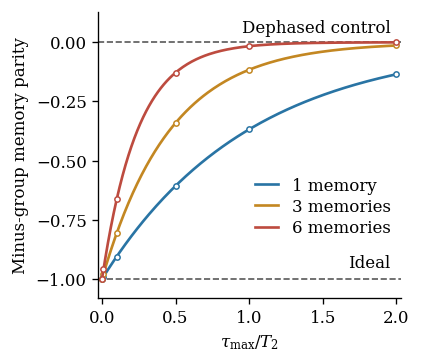

| Memories | Storage / T₂ | Minus parity | Dephased parity |
| --- | --- | --- | --- |
| 1 | 0.00 | -1.000000 | 0 |
| 1 | 0.01 | -0.990050 | 0 |
| 1 | 0.10 | -0.904837 | 0 |
| 1 | 0.50 | -0.606531 | 0 |
| 1 | 1.00 | -0.367879 | 0 |
| 1 | 2.00 | -0.135335 | 0 |
| 3 | 0.00 | -1.000000 | 0 |
| 3 | 0.01 | -0.978690 | 0 |
| 3 | 0.10 | -0.806217 | 0 |
| 3 | 0.50 | -0.340612 | 0 |
| 3 | 1.00 | -0.116017 | 0 |
| 3 | 2.00 | -0.013460 | 0 |
| 6 | 0.00 | -1.000000 | 0 |
| 6 | 0.01 | -0.959736 | 0 |
| 6 | 0.10 | -0.663006 | 0 |
| 6 | 0.50 | -0.128112 | 0 |
| 6 | 1.00 | -0.016413 | 0 |
| 6 | 2.00 | -0.000269 | 0 |

Largest circuit/formula difference: 2.220446049250313e-16
Largest matched-control parity: 0.0


In [15]:
# Hold the circuit fixed and vary common T2; perfect readout isolates storage noise.
coherence_ratios = np.linspace(0.0, 2.0, 201)
coherence_marker_ratios = np.array([0.0, 0.01, 0.1, 0.5, 1.0, 2.0])
coherence_counts = (1, 3, 6)
coherence_rows, coherence_check_rows = [], []
coherence_formula_errors, coherence_control_errors = [], []
coherence_profiles = {}
for N in coherence_counts:
    intervals = np.full(N, TRAIN_ANGLE / OMEGA / N)
    ages = storage_times(intervals, delta_example)
    longest = float(ages.max())
    exposure_ratio = float(ages.sum() / longest)
    coherence_profiles[N] = dict(intervals=intervals, ages=ages,
                                 longest=longest, exposure_ratio=exposure_ratio)
    for ratio in coherence_ratios:
        mean = -np.exp(-ratio * exposure_ratio)
        coherence_rows.append(dict(N=N, storage_over_t2=float(ratio),
            longest_storage_us=longest, total_storage_us=float(ages.sum()),
            total_over_longest_storage=exposure_ratio,
            t2_us=float(longest / ratio) if ratio > 0 else 'infinity',
            minus_parity=float(mean), dephased_parity=0.0))
    for ratio in coherence_marker_ratios:
        t2 = longest / ratio if ratio > 0 else np.inf
        t1 = tphi = 1.5 * t2
        got = calculate(intervals, OMEGA, delta_example, t1, tphi,
                        memory_errors=0.0, q_errors=0.0)
        control = calculate(intervals, OMEGA, delta_example, t1, tphi,
                            memory_errors=0.0, q_errors=0.0, dephased=True)
        expected = -np.exp(-ratio * exposure_ratio)
        error = float(abs(got['observed']['parity'][1] - expected))
        control_error = float(np.max(np.abs(control['observed']['parity'])))
        coherence_formula_errors.append(error)
        coherence_control_errors.append(control_error)
        assert error < ATOL and control_error < ATOL
        coherence_check_rows.append(dict(N=N, storage_over_t2=float(ratio),
            t2_us=float(t2) if np.isfinite(t2) else 'infinity',
            density_matrix_minus=float(got['observed']['parity'][1]),
            analytic_minus=float(expected), dephased_minus=float(control['observed']['parity'][1]),
            formula_error=error, largest_control_parity=control_error))
save_csv('parity_coherence_ratio.csv', coherence_rows)
save_csv('parity_coherence_ratio_checks.csv', coherence_check_rows)

# Fixed canvas and 10-point serif text match the manuscript's one-column panels.
with plt.rc_context({'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
                     'font.size': 10, 'axes.labelsize': 10, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'legend.fontsize': 10,
                     'mathtext.fontset': 'dejavuserif', 'pdf.fonttype': 42}):
    fig, ax = plt.subplots(figsize=(3.404, 3.10))
    fig.subplots_adjust(left=0.23, right=0.97, bottom=0.18, top=0.95)
    colors = {1: '#2974a4', 3: '#c38722', 6: '#bd4b3f'}
    for N in coherence_counts:
        profile = coherence_profiles[N]
        means = -np.exp(-coherence_ratios * profile['exposure_ratio'])
        ax.plot(coherence_ratios, means, color=colors[N], lw=1.6,
                label=f'{N} memory' if N == 1 else f'{N} memories')
        selected = [row for row in coherence_check_rows if row['N'] == N]
        ax.plot([row['storage_over_t2'] for row in selected],
                [row['density_matrix_minus'] for row in selected],
                'o', color=colors[N], ms=3.2, mfc='white', mew=0.9)
    ax.axhline(-1, color='0.35', ls='--', lw=1.0, zorder=0)
    ax.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0)
    ax.text(1.96, -0.97, 'Ideal', ha='right', va='bottom')
    ax.text(1.96, 0.025, 'Dephased control', ha='right', va='bottom')
    ax.set(xlabel=r'$\tau_{\max}/T_2$', ylabel='Minus-group memory parity',
           xlim=(-0.025, 2.03), ylim=(-1.08, 0.13))
    ax.set_xticks([0, 0.5, 1, 1.5, 2])
    ax.set_yticks([-1, -0.75, -0.5, -0.25, 0])
    ax.legend(loc='lower right', bbox_to_anchor=(1, 0.18), frameon=False,
              handlelength=1.4, labelspacing=0.25, borderpad=0.1)
    ax.spines[['top', 'right']].set_visible(False)
    # Keep the exact canvas size: no bbox_inches='tight' on paper exports.
    fig.savefig(OUT / 'parity_coherence_ratio.pdf')
    fig.savefig(OUT / 'parity_coherence_ratio.png', dpi=300)
    plt.show()

coherence_figure_checks = dict(
    density_matrix_cases=len(coherence_check_rows),
    largest_formula_difference=max(coherence_formula_errors),
    largest_dephased_control_parity=max(coherence_control_errors),
    tolerance=ATOL,
    x_axis='longest post-recording memory storage time divided by common T2',
    varied='T2 at fixed drive angles and gate timings; T1=Tphi=1.5*T2',
    memory_readout_error=0.0, schedule_readout_error=0.0,
    memory_counts=list(coherence_counts),
    marker_ratios=coherence_marker_ratios.tolist(),
    profiles=[dict(N=N, longest_storage_us=p['longest'],
                   total_storage_us=float(p['ages'].sum()),
                   total_over_longest_storage=p['exposure_ratio'])
              for N, p in coherence_profiles.items()],
    canvas_inches=[3.404, 3.10], font_points=10)
(OUT / 'parity_coherence_ratio_verification.json').write_text(
    json.dumps(coherence_figure_checks, indent=2) + '\n')
show_table(['Memories', 'Storage / T₂', 'Minus parity', 'Dephased parity'],
           [[row['N'], f"{row['storage_over_t2']:.2f}",
             f"{row['density_matrix_minus']:.6f}", f"{row['dephased_minus']:.2g}"]
            for row in coherence_check_rows])
print('Largest circuit/formula difference:', max(coherence_formula_errors))
print('Largest matched-control parity:', max(coherence_control_errors))

## 16. Save the results

The summary below uses this run's results. The checks test the calculation, not whether the example values match a real processor.

To make a hardware prediction, replace the examples with measured memory lifetimes, gate timings, and both readout error rates for each bit. A fuller model would also include noise on $Q$ and $S$, imperfect gates, and measured error correlations.

In [16]:
checks = dict(kraus_channel_cases=len(channel_errors),
              largest_channel_difference=max(channel_errors),
              interleaved_timing_cases=len(time_errors),
              largest_timing_difference=max(time_errors),
              random_noisy_cases=len(formula_errors),
              largest_parity_formula_difference=max(formula_errors),
              largest_change_in_reduced_q=max(q_state_errors),
              density_matrix_grid_checks=len(grid_errors),
              largest_grid_difference=max(grid_errors),
              memory_sweep_circuits=len(sweep_rows), offset_sweep_circuits=len(offset_rows),
              tolerance=ATOL)
summary = dict(seed=SEED, checks=checks,
               coherence_ratio_figure=coherence_figure_checks,
               assumptions=dict(omega_rad_per_us=OMEGA, train_angle=TRAIN_ANGLE,
                 offset_angle=OFFSET_ANGLE, record_us=RECORD_US, final_wait_us=WAIT_US,
                 t1_us=T1_US, tphi_us=TPHI_US, t2_us=T2_US,
                 memory_assignment_error=MEMORY_READOUT, schedule_assignment_error=SCHEDULE_READOUT,
                 calibration_status="Illustrative assumptions, not measured backend calibration",
                 excluded="Q/S quantum noise; entangling/basis-gate noise; heating; correlations; drift"),
               example_memory_count=N_EXAMPLE, example_storage_times_us=ages_example.tolist(),
               examples=example_rows, all_noise_by_memory_count=all_rows, shot_plan=shot_plan,
               versions=dict(python=platform.python_version(), numpy=np.__version__, matplotlib=matplotlib.__version__))
(OUT / "verification_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
combined = example_results["all three sources"]["observed"]
report = (
    f"**For the example with {N_EXAMPLE} memories**, the reported minus parity is "
    f"**{combined['parity'][1]:.4f}**, compared with −1 ideally and "
    f"{control_example['observed']['parity'][1]:.2g} for the dephased control. "
    f"The plus parity is {combined['parity'][0]:.4f}, and "
    f"{100*combined['p'][1]:.1f}% of runs are reported as minus.\n\n"
    "**What this says:** the signal survives the example noise but loses contrast. "
    "Earlier records wait longer, and adding memories compounds storage and readout losses. "
    "Schedule misclassification is especially costly when the true minus outcome is rare.\n\n"
    "**What it does not say:** it does not establish a device-specific operating point or complete "
    "experimental robustness. Those require measured parameters and the additional noise sources listed above."
)
display(Markdown(report))
print("All numerical checks passed.")
print("Results saved in", OUT)

**For the example with 6 memories**, the reported minus parity is **-0.3682**, compared with −1 ideally and 0 for the dephased control. The plus parity is 0.1294, and 26.0% of runs are reported as minus.

**What this says:** the signal survives the example noise but loses contrast. Earlier records wait longer, and adding memories compounds storage and readout losses. Schedule misclassification is especially costly when the true minus outcome is rare.

**What it does not say:** it does not establish a device-specific operating point or complete experimental robustness. Those require measured parameters and the additional noise sources listed above.

All numerical checks passed.
Results saved in outputs/memory_robustness


## Sources

- [Ideal circuit verification](ideal_circuit_verification.ipynb): visibility, system survival, and both parity groups.
- Manuscript (not included in this analysis package): `eq:visibility`, `eq:antizeno`, and the parity discussion after `eq:plusbranch`.
- [IBM Quantum noise guide](https://quantum.cloud.ibm.com/docs/en/guides/build-noise-models): quantum channels and classical readout errors.
- [Qiskit Aer relaxation documentation](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.thermal_relaxation_error.html): relaxation parameters and $T_2\le2T_1$.

The calculation uses explicit NumPy density matrices. Qiskit is not required.